In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
games = pd.read_csv("games.csv")

### 1. Overview

Keep only the columns from ```NumImplementations``` to ```Rank:wargames```

In [3]:
FIRST, LAST = "NumImplementations", "Rank:wargames"
cols = list(games.columns)
target = cols[cols.index(FIRST): cols.index(LAST) + 1]
rank_cols = [c for c in target if c.startswith("Rank:")]
genre_cols = [c for c in rank_cols if c != "Rank:boardgame"]
print(len(target))

games_target = games[target].copy()
print(len(games_target))

12
21925


In [4]:
games_target.head(10)

,NumImplementations,IsReimplementation,Family,Kickstarted,ImagePath,Rank:boardgame,Rank:strategygames,Rank:abstracts,Rank:familygames,Rank:thematic,Rank:cgs,Rank:wargames
0,0,0,Classic Line (Valley Games),0,https://cf.geekdo-images.com/rpwCZAjYLD940NWwP...,316,180,21926,21926,21926,21926,21926
1,2,1,NaN,0,https://cf.geekdo-images.com/oQYhaJx5Lg3KcGis2...,3993,1577,21926,21926,21926,21926,21926
2,1,0,Euro Classics (Reiner Knizia),0,https://cf.geekdo-images.com/o9-sNXmFS_TLAb7Zl...,224,166,21926,21926,21926,21926,21926
3,0,0,NaN,0,https://cf.geekdo-images.com/nYiYhUlatT2DpyXaJ...,5345,21926,21926,21926,21926,21926,21926
4,0,0,3M Bookshelf,0,https://cf.geekdo-images.com/3C--kJRhi6kTPHsr9...,290,220,21926,21926,21926,21926,21926
5,0,0,NaN,0,https://cf.geekdo-images.com/277POF80AUz2ZE9XS...,10766,21926,21926,21926,21926,21926,21926
6,0,0,NaN,0,https://cf.geekdo-images.com/LAzZ0q7ok2x92yQxj...,1969,21926,137,21926,21926,21926,21926
7,0,0,NaN,0,https://cf.geekdo-images.com/-pwShxFPJWrxye8o1...,9144,21926,21926,21926,21926,21926,21926
8,0,0,El Grand,0,https://cf.geekdo-images.com/lWotCtplnl0sI3bS_...,2948,1297,21926,21926,21926,21926,21926
9,3,1,Elfenroads,0,https://cf.geekdo-images.com/Ea4jN5Ko5bPrXrU_A...,1117,21926,21926,308,21926,21926,21926


12 columns to analyze and 21925 rows in the dataset

Let's have an overview of the 12 columns

In [5]:
overview = pd.DataFrame({
    "dtype": games_target.dtypes.astype(str),
    "non-null": games_target.notna().sum(),
    "missing": games_target.isna().sum(),
    "missing %": (games_target.isna().mean() * 100).round(1),
    "unique": games_target.nunique(),
})
overview

,dtype,non-null,missing,missing %,unique
NumImplementations,int64,21925,0,0.0,23
IsReimplementation,int64,21925,0,0.0,2
Family,str,6663,15262,69.6,1456
Kickstarted,int64,21925,0,0.0,2
ImagePath,str,21908,17,0.1,21904
Rank:boardgame,int64,21925,0,0.0,21579
Rank:strategygames,int64,21925,0,0.0,2320
Rank:abstracts,int64,21925,0,0.0,1116
Rank:familygames,int64,21925,0,0.0,2317
Rank:thematic,int64,21925,0,0.0,1225


```Family``` and ```ImagePath``` are the only columns having missing values. For the first category, ~70% of the entires are missing

Here instead is a statistical summary of the 12 columns

In [6]:
games_target.describe(include="all").T[["count", "unique", "mean", "std", "min", "50%", "max"]].round(2)

,count,unique,mean,std,min,50%,max
NumImplementations,21925.0,NaN,0.308734,0.848095,0.0,0.0,38.0
IsReimplementation,21925.0,NaN,0.116762,0.321143,0.0,0.0,1.0
Family,6663,1456,NaN,NaN,NaN,NaN,NaN
Kickstarted,21925.0,NaN,0.153341,0.360324,0.0,0.0,1.0
ImagePath,21908,21904,NaN,NaN,NaN,NaN,NaN
Rank:boardgame,21925.0,NaN,11019.514071,6372.926817,1.0,11022.0,21926.0
Rank:strategygames,21925.0,NaN,19729.826956,6389.614077,1.0,21926.0,21926.0
Rank:abstracts,21925.0,NaN,20839.347184,4695.170448,1.0,21926.0,21926.0
Rank:familygames,21925.0,NaN,19732.270011,6387.089598,1.0,21926.0,21926.0
Rank:thematic,21925.0,NaN,20736.185815,4893.928466,1.0,21926.0,21926.0


Overview on the columns containing a ranking

In [7]:
df = games[["BGGId", "Name", "YearPublished"] + target].copy()
UNRANKED = int(df[rank_cols].max().max())
df[rank_cols] = df[rank_cols].replace(UNRANKED, np.nan)

check = pd.DataFrame({
    "ranked games": df[rank_cols].notna().sum(),
    "unranked games": df[rank_cols].isna().sum(),
    "best rank": df[rank_cols].min(),
    "worst rank": df[rank_cols].max(),
    "ties": [df[c].dropna().duplicated().sum() for c in rank_cols],
})
check["missing positions"] = (check["worst rank"] - check["ranked games"]).astype(int)
check

,ranked games,unranked games,best rank,worst rank,ties,missing positions
Rank:boardgame,21578,347,1.0,21684.0,0,106
Rank:strategygames,2319,19606,1.0,2328.0,0,9
Rank:abstracts,1115,20810,1.0,1116.0,0,1
Rank:familygames,2316,19609,1.0,2316.0,0,0
Rank:thematic,1224,20701,1.0,1228.0,0,4
Rank:cgs,303,21622,1.0,303.0,0,0
Rank:wargames,3530,18395,1.0,3531.0,0,1


### 2. ```NumImplementations```

count    21925.00
mean         0.31
std          0.85
min          0.00
25%          0.00
50%          0.00
75%          0.00
max         38.00


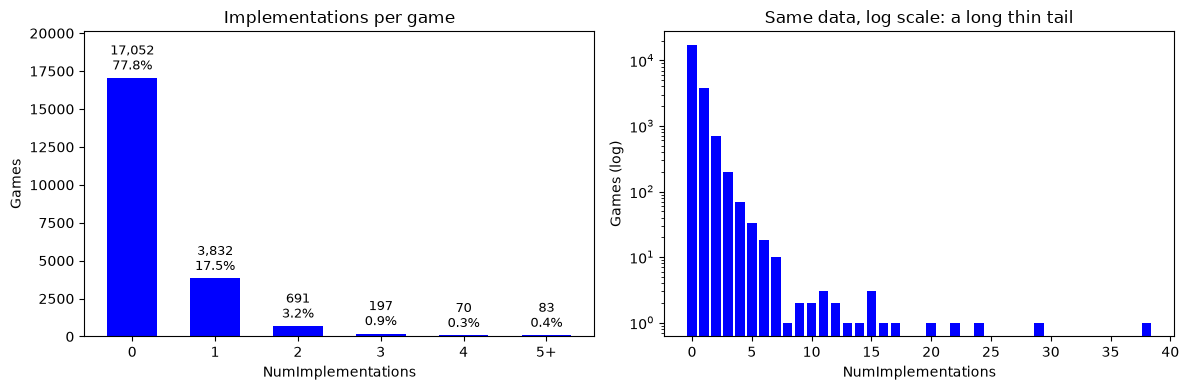

In [ ]:
n = df["NumImplementations"]
print(n.describe().round(2).to_string())

counts = n.clip(upper=5).value_counts().sort_index()
labels = [str(i) for i in counts.index[:-1]] + ["5+"]
full = n.value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
bars = ax1.bar(labels, counts.values, color="blue", width=0.6)
ax1.bar_label(bars, labels=[f"{v:,}\n{v / len(n):.1%}" for v in counts.values],
              padding=3, fontsize=9)
ax1.set(title="Implementations per game", xlabel="NumImplementations", ylabel="Games")
ax1.set_ylim(0, counts.max() * 1.18)
ax1.grid(axis="x", visible=False)

ax2.bar(full.index, full.values, color="blue", width=0.8)
ax2.set_yscale("log")
ax2.set(title="Same data, log scale", xlabel="NumImplementations", ylabel="Games (log)")
ax2.grid(axis="x", visible=False)
plt.tight_layout()
plt.show();

Most of the games (~79%) have 0 implementation. Let's look at the top 10 games with the highest number of implementation

In [9]:
df.nlargest(10, "NumImplementations")[["Name", "YearPublished", "NumImplementations", "Rank:boardgame"]]

,Name,YearPublished,NumImplementations,Rank:boardgame
221,Fluxx,1997,38,9171.0
12,Catan,1995,29,427.0
1401,Munchkin,2001,24,4761.0
967,Clue,1949,22,8945.0
159,Risk,1959,20,20741.0
673,Carcassonne,2000,17,187.0
10482,Quarriors!,2011,16,940.0
1051,Monopoly,1933,15,21678.0
11807,Love Letter,2012,15,291.0
12068,ZnajZnak,2012,15,13976.0


### 3. ```IsReimplementation```

In [10]:
r = df["IsReimplementation"]
print(r.value_counts().rename({0: "original", 1: "reimplementation"}).to_frame("games").assign(share=lambda x: (x.games / len(r)).map("{:.1%}".format)))

                    games  share
IsReimplementation              
original            19365  88.3%
reimplementation     2560  11.7%


Most of the games (~88%) are original

### 4. ```Familiy```

Missing family: 15,262 games (69.6%)
Games with a family: 6,663 in 1,456 different families
Families with a single game: 402 (27.6% of families)


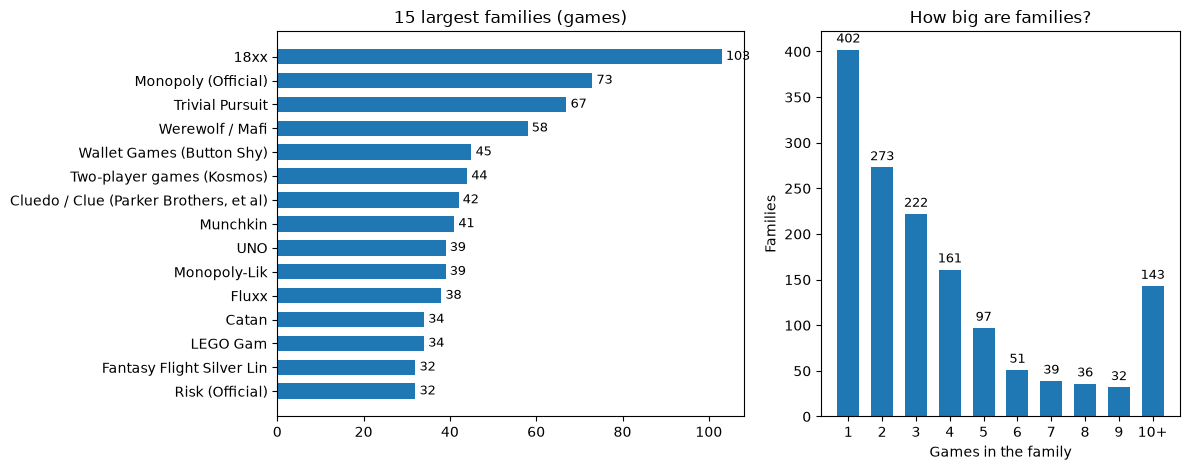

In [11]:
fam = df["Family"]
fam_counts = fam.value_counts()
print(f"Missing family: {fam.isna().sum():,} games ({fam.isna().mean():.1%})")
print(f"Games with a family: {fam.notna().sum():,} in {fam.nunique():,} different families")
print(f"Families with a single game: {(fam_counts == 1).sum():,} ({(fam_counts == 1).mean():.1%} of families)")

top = fam_counts.head(15).iloc[::-1]
sizes = fam_counts.clip(upper=10).value_counts().sort_index()
size_labels = [str(i) for i in sizes.index[:-1]] + ["10+"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
bars = ax1.barh(top.index, top.values, height=0.65)
ax1.bar_label(bars, padding=3, fontsize=9)
ax1.set(title="15 largest families (games)")
ax1.grid(axis="y", visible=False)

bars = ax2.bar(size_labels, sizes.values, width=0.65)
ax2.bar_label(bars, padding=3, fontsize=9)
ax2.set(title="How big are families?", xlabel="Games in the family", ylabel="Families")
ax2.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

### 5. ```Kickstarted```

Kickstarted games: 3,362 of 21,925 (15.3%)


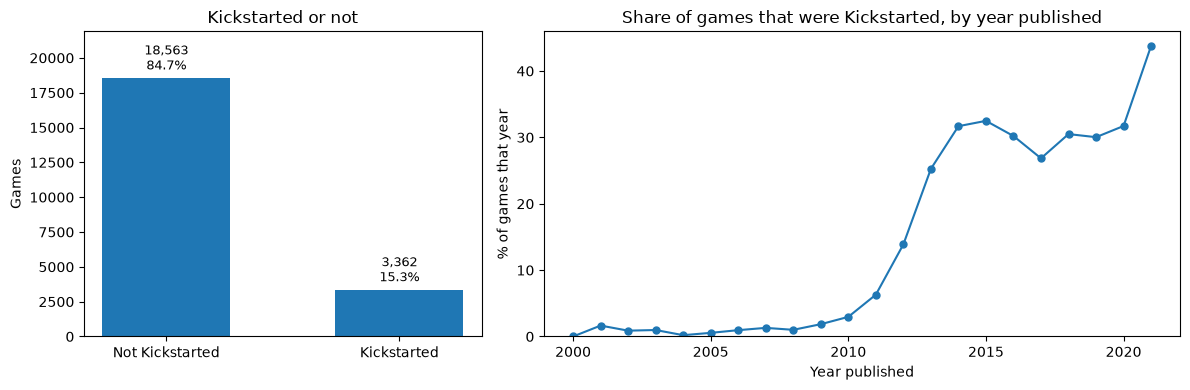

YearPublished,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
share,0.0,0.016,0.009,0.01,0.002,0.005,0.01,0.013,0.01,0.019,...,0.139,0.253,0.317,0.325,0.302,0.268,0.305,0.3,0.317,0.438
games,303.0,304.000,341.000,410.00,501.000,547.000,524.00,539.000,597.00,647.000,...,843.000,875.000,1032.000,1185.000,1321.000,1356.000,1351.000,1302.0,927.000,660.000


In [12]:
k = df["Kickstarted"]
print(f"Kickstarted games: {k.sum():,} of {len(k):,} ({k.mean():.1%})")

# context: YearPublished, to see how the share changes over time
by_year = (df[df["YearPublished"].between(2000, 2021)]
           .groupby("YearPublished")["Kickstarted"].agg(share="mean", games="size"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.6]})
kc = k.value_counts().sort_index()
bars = ax1.bar(["Not Kickstarted", "Kickstarted"], kc.values, width=0.55)
ax1.bar_label(bars, labels=[f"{v:,}\n{v / len(k):.1%}" for v in kc.values], padding=3, fontsize=9)
ax1.set(title="Kickstarted or not", ylabel="Games")
ax1.set_ylim(0, kc.max() * 1.18)
ax1.grid(axis="x", visible=False)

ax2.plot(by_year.index, by_year["share"] * 100, marker="o", markersize=5)
ax2.set(title="Share of games that were Kickstarted, by year published", xlabel="Year published", ylabel="% of games that year")
ax2.set_ylim(0, None)
plt.tight_layout()
plt.show()
by_year.T.round(3)

### 6. ```ImagePath```

Not useful

### 7. ```Rankings```

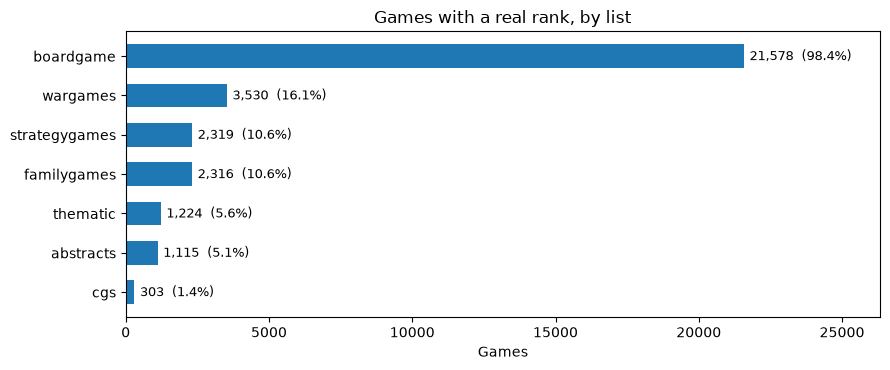

In [13]:
ranked = df[rank_cols].notna().sum().sort_values()
fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.barh([c.replace("Rank:", "") for c in ranked.index], ranked.values, height=0.6)
ax.bar_label(bars, labels=[f"{v:,}  ({v / len(df):.1%})" for v in ranked.values], padding=4, fontsize=9)
ax.set(title="Games with a real rank, by list", xlabel="Games")
ax.set_xlim(0, ranked.max() * 1.22)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()